# Lettura preliminare delle curve AFM `.jpk-force`

Notebook operativo per leggere la cartella **`Curve di forza belle`**, estrarre le informazioni principali dai file JPK, visualizzare alcune curve e produrre una tabella riassuntiva.

**Come usarlo**

1. Metti questo notebook nella stessa directory che contiene la cartella `Curve di forza belle`.
2. Apri il notebook con Jupyter / VS Code.
3. Esegui le celle in ordine.

La struttura attesa è:

```text
cartella_di_lavoro/
├── AFM_JPK_reader_exploration.ipynb
└── Curve di forza belle/
    ├── T47DR_t48h_cito_20260318/
    ├── T47DR_t48h_nucleo_20260318/
    ├── Petri20k_MCF7R_t48h_cito_20260225/
    └── Petri20k_MCF7R_t48h_nucleo_20260225/
```

Questo notebook **non fa ancora il fit finale del modulo di Young**. Prima costruisce il loader robusto e il controllo qualità di base. Il fit Hertz-like verrà dopo, quando avremo verificato bene orientamento, unità e convenzioni sperimentali.

In [1]:
from pathlib import Path
import zipfile
import re
import math
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Impostazioni display
pd.set_option('display.max_columns', 80)
pd.set_option('display.width', 160)

# Cartella dati. Il notebook va lanciato dalla directory che contiene "Curve di forza belle".
DATA_DIR = Path("Curve di forza belle")

# Cartelle output create automaticamente
OUT_DIR = Path("afm_output")
PLOTS_DIR = OUT_DIR / "plots_overview"
CSV_DIR = OUT_DIR / "csv_curves"
OUT_DIR.mkdir(exist_ok=True)
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
CSV_DIR.mkdir(parents=True, exist_ok=True)

print("Working directory:", Path.cwd())
print("Data directory:", DATA_DIR.resolve())
print("Data directory exists:", DATA_DIR.exists())

Working directory: c:\Users\giaco\OneDrive\Desktop\AFM
Data directory: C:\Users\giaco\OneDrive\Desktop\AFM\Curve di forza belle
Data directory exists: True


## 1. Funzioni per leggere i file `.jpk-force`

I file `.jpk-force` sono archivi ZIP interni. Ogni file contiene header testuali e canali binari, ad esempio `vDeflection.dat` e `verticalTipPosition.dat`.

Qui implementiamo un parser minimale, pensato specificamente per l'esplorazione iniziale dei tuoi file.

In [2]:
def parse_properties(text_or_bytes):
    """Parse semplice di file .properties JPK: righe key=value, ignorando commenti."""
    if isinstance(text_or_bytes, bytes):
        text = text_or_bytes.decode('utf-8', errors='replace')
    else:
        text = str(text_or_bytes)
    props = {}
    for line in text.splitlines():
        line = line.strip()
        if not line or line.startswith('#') or '=' not in line:
            continue
        k, v = line.split('=', 1)
        props[k.strip()] = v.strip()
    return props


def safe_float(x, default=np.nan):
    try:
        if x is None:
            return default
        x = str(x).replace('\\:', ':')
        if x.lower() == 'nan':
            return np.nan
        return float(x)
    except Exception:
        return default


def channel_lcd_index(shared_props, channel_name):
    """Trova l'indice lcd-info associato a un canale, per esempio vDeflection -> 1."""
    pattern = re.compile(r"lcd-info\.(\d+)\.channel\.name")
    for k, v in shared_props.items():
        m = pattern.fullmatch(k)
        if m and v == channel_name:
            return int(m.group(1))
    return None


def channel_type(shared_props, channel_name):
    idx = channel_lcd_index(shared_props, channel_name)
    if idx is None:
        return None
    return shared_props.get(f"lcd-info.{idx}.type")


def read_raw_channel(zf, segment_id, channel_name, shared_props):
    """Legge un canale binario. Nei file osservati i float sono big-endian 32-bit."""
    name = f"segments/{segment_id}/channels/{channel_name}.dat"
    if name not in zf.namelist():
        return None
    raw = zf.read(name)
    ctype = channel_type(shared_props, channel_name)
    if ctype == 'float-data':
        arr = np.frombuffer(raw, dtype='>f4').astype(float)
    elif ctype == 'integer-data':
        # Non usato per i canali principali sotto, ma lasciato per ispezione.
        arr = np.frombuffer(raw, dtype='>i4').astype(float)
    else:
        # fallback ragionevole per i canali principali JPK
        arr = np.frombuffer(raw, dtype='>f4').astype(float)
    return arr


def generated_time_channel(segment_props):
    n = int(float(segment_props.get('channel.time.data.num-points', segment_props.get('force-segment-header.num-points', 0))))
    start = safe_float(segment_props.get('channel.time.data.start'), 0.0)
    step = safe_float(segment_props.get('channel.time.data.step'), np.nan)
    if n <= 0 or not np.isfinite(step):
        return None
    return start + step * np.arange(n)


def conversion_multiplier(shared_props, channel_name, conversion_name):
    """Estrae il multiplier di una conversione lineare per un canale."""
    idx = channel_lcd_index(shared_props, channel_name)
    if idx is None:
        return np.nan
    return safe_float(shared_props.get(f"lcd-info.{idx}.conversion-set.conversion.{conversion_name}.scaling.multiplier"))


def conversion_offset(shared_props, channel_name, conversion_name):
    idx = channel_lcd_index(shared_props, channel_name)
    if idx is None:
        return np.nan
    return safe_float(shared_props.get(f"lcd-info.{idx}.conversion-set.conversion.{conversion_name}.scaling.offset"), 0.0)


def read_jpk_segment(file_path, segment_id=0):
    """
    Legge un segmento di un file .jpk-force.
    Restituisce df, metadata_globali, metadata_segmento.
    """
    file_path = Path(file_path)
    with zipfile.ZipFile(file_path, 'r') as zf:
        names = set(zf.namelist())
        global_props = parse_properties(zf.read('header.properties')) if 'header.properties' in names else {}
        shared_props = parse_properties(zf.read('shared-data/header.properties')) if 'shared-data/header.properties' in names else {}
        seg_header_name = f'segments/{segment_id}/segment-header.properties'
        if seg_header_name not in names:
            raise ValueError(f"Segmento {segment_id} non trovato in {file_path.name}")
        seg_props = parse_properties(zf.read(seg_header_name))

        # Canali principali
        z_tip = read_raw_channel(zf, segment_id, 'verticalTipPosition', shared_props)
        vdefl_V = read_raw_channel(zf, segment_id, 'vDeflection', shared_props)
        h = read_raw_channel(zf, segment_id, 'height', shared_props)
        t = generated_time_channel(seg_props)

        if z_tip is None or vdefl_V is None:
            raise ValueError(f"Canali principali mancanti in {file_path.name}, segmento {segment_id}")

        n = min(len(z_tip), len(vdefl_V))
        z_tip = z_tip[:n]
        vdefl_V = vdefl_V[:n]
        if h is not None:
            h = h[:n]
        if t is not None:
            t = t[:n]

        # Conversione vDeflection: V -> deflection distance -> force.
        # Dai tuoi file: distance multiplier ~ 1.3996e-8 m/V, force multiplier ~ 0.0800 N/m.
        sens_m_per_V = conversion_multiplier(shared_props, 'vDeflection', 'distance')
        spring_N_per_m = conversion_multiplier(shared_props, 'vDeflection', 'force')
        if not np.isfinite(sens_m_per_V):
            sens_m_per_V = np.nan
        if not np.isfinite(spring_N_per_m):
            spring_N_per_m = np.nan

        deflection_m = vdefl_V * sens_m_per_V if np.isfinite(sens_m_per_V) else np.full_like(vdefl_V, np.nan)
        force_N = deflection_m * spring_N_per_m if np.isfinite(spring_N_per_m) else np.full_like(vdefl_V, np.nan)

        df = pd.DataFrame({
            'point': np.arange(n),
            'time_s': t if t is not None else np.nan,
            'z_tip_m': z_tip,
            'z_tip_um': z_tip * 1e6,
            'vDeflection_V': vdefl_V,
            'deflection_m': deflection_m,
            'deflection_nm': deflection_m * 1e9,
            'force_N': force_N,
            'force_nN': force_N * 1e9,
        })
        if h is not None:
            df['height_raw'] = h

        meta = {
            'file': str(file_path),
            'file_name': file_path.name,
            'group': file_path.parent.name,
            'segment_id': segment_id,
            'segment_style': seg_props.get('force-segment-header.settings.segment-settings.style', seg_props.get('force-segment-header.settings.style')),
            'segment_name': seg_props.get('force-segment-header.name.name'),
            'num_points_header': safe_float(seg_props.get('force-segment-header.num-points')),
            'num_points_read': n,
            'duration_s': safe_float(seg_props.get('force-segment-header.duration')),
            'time_stamp': seg_props.get('force-segment-header.time-stamp'),
            'cantilever_id': seg_props.get('force-segment-header.environment.cantilever-calibration-info.cantilever-id'),
            'cantilever_name': seg_props.get('force-segment-header.environment.cantilever-calibration-info.cantilever-name'),
            'spring_N_per_m': spring_N_per_m,
            'sensitivity_m_per_V': sens_m_per_V,
            'tip_radius': seg_props.get('force-segment-header.environment.cantilever-calibration-info.tip-radius'),
            'tip_half_angle': seg_props.get('force-segment-header.environment.cantilever-calibration-info.tip-half-angle'),
            'setpoint': safe_float(seg_props.get('force-segment-header.settings.segment-settings.setpoint')),
        }
        return df, meta, global_props, shared_props, seg_props


def list_jpk_files(data_dir=DATA_DIR):
    data_dir = Path(data_dir)
    return sorted(data_dir.rglob('*.jpk-force'))

## 2. Controllo della cartella e conteggio dei file

In [3]:
files = list_jpk_files(DATA_DIR)
print(f"Numero di file .jpk-force trovati: {len(files)}")

if len(files) == 0:
    raise FileNotFoundError(
        "Non trovo file .jpk-force. Controlla che DATA_DIR punti alla cartella 'Curve di forza belle'."
    )

# Tabella file-gruppo
file_table = pd.DataFrame({
    'path': [str(p) for p in files],
    'file_name': [p.name for p in files],
    'group': [p.parent.name for p in files],
})

display(file_table.groupby('group').size().reset_index(name='n_curves'))
display(file_table.head())

Numero di file .jpk-force trovati: 257


,group,n_curves
0,Petri20k_MCF7R_t48h_cito_20260225,55
1,Petri20k_MCF7R_t48h_nucleo_20260225,60
2,T47DR_t48h_cito_20260318,59
3,T47DR_t48h_nucleo_20260318,83


,path,file_name,group
0,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225
1,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225
2,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225
3,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0007.jpk-force,Petri20k_MCF7R_t48h_cito_20260225
4,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0008.jpk-force,Petri20k_MCF7R_t48h_cito_20260225


## 3. Ispezione di un singolo file

Leggiamo il primo file, mostriamo metadati essenziali e plottiamo approach/retract.

In [4]:
example_file = files[0]
print("Esempio:", example_file)

# Segmenti tipici: 0 = extend/approach, 1 = retract
for seg in [0, 1]:
    try:
        df_seg, meta_seg, *_ = read_jpk_segment(example_file, segment_id=seg)
        print(f"\nSegmento {seg}")
        for k in ['segment_name', 'segment_style', 'num_points_read', 'duration_s', 'spring_N_per_m', 'sensitivity_m_per_V', 'cantilever_name']:
            print(f"  {k}: {meta_seg.get(k)}")
        display(df_seg.head())
    except Exception as e:
        print(f"Segmento {seg} non leggibile: {e}")

Esempio: Curve di forza belle\Petri20k_MCF7R_t48h_cito_20260225\cito-0000.jpk-force

Segmento 0
  segment_name: extend-spm
  segment_style: extend
  num_points_read: 6000
  duration_s: 1.0
  spring_N_per_m: 0.11882854247819882
  sensitivity_m_per_V: 1.0902786667117663e-08
  cantilever_name: MLCT-BIO-Triangular


,point,time_s,z_tip_m,z_tip_um,vDeflection_V,deflection_m,deflection_nm,force_N,force_nN,height_raw
0,0,0.000083,-0.000009,-9.411679,-0.002549,-2.778649e-11,-0.027786,-3.301828e-12,-0.003302,-1.731205e+09
1,1,0.000250,-0.000009,-9.412655,-0.000184,-2.009426e-12,-0.002009,-2.387772e-13,-0.000239,-1.730781e+09
2,2,0.000417,-0.000009,-9.413626,0.002801,3.053934e-11,0.030539,3.628945e-12,0.003629,-1.730358e+09
3,3,0.000583,-0.000009,-9.414609,0.004604,5.019405e-11,0.050194,5.964486e-12,0.005964,-1.729937e+09
4,4,0.000750,-0.000009,-9.415619,0.003924,4.278044e-11,0.042780,5.083537e-12,0.005084,-1.729515e+09



Segmento 1
  segment_name: retract-spm
  segment_style: retract
  num_points_read: 6000
  duration_s: 1.0
  spring_N_per_m: 0.11882854247819882
  sensitivity_m_per_V: 1.0902786667117663e-08
  cantilever_name: MLCT-BIO-Triangular


,point,time_s,z_tip_m,z_tip_um,vDeflection_V,deflection_m,deflection_nm,force_N,force_nN,height_raw
0,0,0.000083,-0.000015,-15.422782,0.491876,5.362820e-09,5.362820,6.372561e-10,0.637256,-46054326.0
1,1,0.000250,-0.000015,-15.422209,0.452404,4.932463e-09,4.932463,5.861174e-10,0.586117,-45968748.0
2,2,0.000417,-0.000015,-15.421027,0.468966,5.113040e-09,5.113040,6.075751e-10,0.607575,-45950072.0
3,3,0.000583,-0.000015,-15.420144,0.457931,4.992722e-09,4.992722,5.932779e-10,0.593278,-46003619.0
4,4,0.000750,-0.000015,-15.419120,0.459886,5.014041e-09,5.014041,5.958112e-10,0.595811,-46110322.0


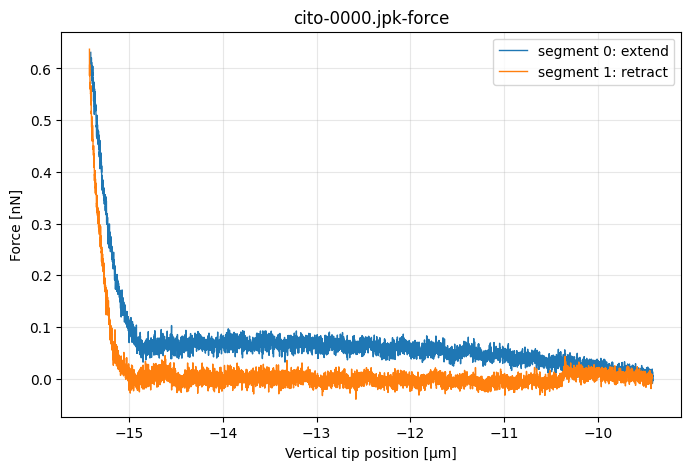

In [5]:
fig, ax = plt.subplots(figsize=(8, 5))
for seg in [0, 1]:
    try:
        df_seg, meta_seg, *_ = read_jpk_segment(example_file, segment_id=seg)
        label = f"segment {seg}: {meta_seg.get('segment_style')}"
        ax.plot(df_seg['z_tip_um'], df_seg['force_nN'], lw=1, label=label)
    except Exception:
        pass
ax.set_xlabel('Vertical tip position [µm]')
ax.set_ylabel('Force [nN]')
ax.set_title(example_file.name)
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 4. Estrazione automatica delle informazioni principali

Per ogni curva estraiamo una riga riassuntiva. Per ora usiamo soprattutto il segmento `0` perché di solito corrisponde all'extend/approach.

Le feature sono volutamente semplici:

- numero di punti;
- range in z;
- forza minima/massima;
- rumore di baseline, stimato sul primo 20% della curva;
- forza massima dopo sottrazione della baseline;
- metadati di calibrazione: sensitivity e spring constant.

In [6]:
def summarize_curve(file_path, segment_id=0, baseline_fraction=0.20):
    try:
        df, meta, *_ = read_jpk_segment(file_path, segment_id=segment_id)
        n = len(df)
        nbase = max(10, int(baseline_fraction * n))
        base = df['force_nN'].iloc[:nbase].to_numpy()
        baseline_nN = float(np.nanmedian(base))
        noise_pN = float(np.nanstd(base) * 1000.0)
        force_corr = df['force_nN'].to_numpy() - baseline_nN
        z = df['z_tip_um'].to_numpy()
        row = {
            'status': 'ok',
            'file': str(file_path),
            'file_name': Path(file_path).name,
            'group': Path(file_path).parent.name,
            'segment_id': segment_id,
            'segment_style': meta.get('segment_style'),
            'segment_name': meta.get('segment_name'),
            'n_points': n,
            'z_min_um': float(np.nanmin(z)),
            'z_max_um': float(np.nanmax(z)),
            'z_range_um': float(np.nanmax(z) - np.nanmin(z)),
            'force_min_nN': float(np.nanmin(df['force_nN'])),
            'force_max_nN': float(np.nanmax(df['force_nN'])),
            'force_corr_max_nN': float(np.nanmax(force_corr)),
            'force_corr_min_nN': float(np.nanmin(force_corr)),
            'baseline_nN': baseline_nN,
            'baseline_noise_pN': noise_pN,
            'spring_N_per_m': meta.get('spring_N_per_m'),
            'sensitivity_m_per_V': meta.get('sensitivity_m_per_V'),
            'cantilever_name': meta.get('cantilever_name'),
            'cantilever_id': meta.get('cantilever_id'),
            'tip_radius': meta.get('tip_radius'),
            'tip_half_angle': meta.get('tip_half_angle'),
            'time_stamp': meta.get('time_stamp'),
        }
        return row
    except Exception as e:
        return {
            'status': 'error',
            'file': str(file_path),
            'file_name': Path(file_path).name,
            'group': Path(file_path).parent.name,
            'segment_id': segment_id,
            'error': repr(e),
        }

summary_rows = [summarize_curve(p, segment_id=0) for p in files]
summary = pd.DataFrame(summary_rows)
summary_path = OUT_DIR / 'summary_segment0.csv'
summary.to_csv(summary_path, index=False)

print("Salvato:", summary_path)
print(summary['status'].value_counts(dropna=False))
display(summary.head())

Salvato: afm_output\summary_segment0.csv
status
ok    257
Name: count, dtype: int64


,status,file,file_name,group,segment_id,segment_style,segment_name,n_points,z_min_um,z_max_um,z_range_um,force_min_nN,force_max_nN,force_corr_max_nN,force_corr_min_nN,baseline_nN,baseline_noise_pN,spring_N_per_m,sensitivity_m_per_V,cantilever_name,cantilever_id,tip_radius,tip_half_angle,time_stamp
0,ok,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0000.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.409008,-9.411679,5.997330,-0.010746,0.631120,0.609161,-0.032705,0.021959,11.573731,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:09\:43.503 +0100
1,ok,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0005.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,4700,-15.592912,-10.896858,4.696054,0.002368,0.741301,0.706989,-0.031944,0.034312,10.248385,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:47.886 +0100
2,ok,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0006.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,5413,-15.767386,-10.357957,5.409429,-0.090425,0.596325,0.570457,-0.116293,0.025869,17.823069,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:49.808 +0100
3,ok,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0007.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.621139,-9.624797,5.996342,0.071084,0.656569,0.553840,-0.031645,0.102729,9.911915,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:51.934 +0100
4,ok,Curve di forza belle\Petri20k_MCF7R_t48h_cito_...,cito-0008.jpk-force,Petri20k_MCF7R_t48h_cito_20260225,0,extend,extend-spm,6000,-15.645828,-9.651365,5.994463,0.013170,0.813682,0.767406,-0.033106,0.046276,10.975507,0.118829,1.090279e-08,MLCT-BIO-Triangular,2300FE,NaN,NaN,2026-02-25 09\:11\:54.151 +0100


In [7]:
# Statistiche aggregate per gruppo
numeric_cols = ['n_points', 'z_range_um', 'force_corr_max_nN', 'baseline_noise_pN', 'spring_N_per_m', 'sensitivity_m_per_V']
agg = summary[summary['status'] == 'ok'].groupby('group')[numeric_cols].agg(['count', 'mean', 'std', 'min', 'max'])
display(agg)

n_points                                      z_range_um                                         force_corr_max_nN  \
                                       count         mean         std   min   max      count      mean       std       min       max             count   
group                                                                                                                                                    
Petri20k_MCF7R_t48h_cito_20260225         55  5782.054545  405.923247  4700  6000         55  5.777995  0.405623  4.696054  5.997728                55   
Petri20k_MCF7R_t48h_nucleo_20260225       60  5925.483333  239.929685  4437  6000         60  5.921144  0.239721  4.433225  5.996925                60   
T47DR_t48h_cito_20260318                  59  5754.322034  468.369418  4165  6000         59  5.748267  0.468454  4.159080  5.995716                59   
T47DR_t48h_nucleo_20260318                83  5762.433735  426.740059  4037  6000         83  5.756663  0.426873  4.029774  5.995932                83   

                                                                            baseline_noise_pN                                           spring_N_per_m  \
                                         mean       std       min       max             count       mean       std       min        max          count   
group                                                                                                                                                    
Petri20k_MCF7R_t48h_cito_20260225    0.658598  0.113313  0.399733  0.920557                55  12.908920  5.604200  8.815375  46.649339             55   
Petri20k_MCF7R_t48h_nucleo_20260225  0.684453  0.099282  0.354931  0.898758                60  10.810986  4.901091  8.202022  37.767244             60   
T47DR_t48h_cito_20260318             0.560745  0.068067  0.389520  0.739601                59   8.371706  1.347727  6.510368  13.064927             59   
T47DR_t48h_nucleo_20260318           0.557889  0.072090  0.421699  0.742799                83   8.924869  2.316176  6.808593  19.772120             83   

                                                                       sensitivity_m_per_V                                                 
                                         mean  std       min       max               count          mean  std           min           max  
group                                                                                                                                      
Petri20k_MCF7R_t48h_cito_20260225    0.118829  0.0  0.118829  0.118829                  55  1.090279e-08  0.0  1.090279e-08  1.090279e-08  
Petri20k_MCF7R_t48h_nucleo_20260225  0.118829  0.0  0.118829  0.118829                  60  1.090279e-08  0.0  1.090279e-08  1.090279e-08  
T47DR_t48h_cito_20260318             0.080043  0.0  0.080043  0.080043                  59  1.399632e-08  0.0  1.399632e-08  1.399632e-08  
T47DR_t48h_nucleo_20260318           0.080043  0.0  0.080043  0.080043                  83  1.399632e-08  0.0  1.399632e-08  1.399632e-08

## 5. Plot automatici di curve rappresentative

Generiamo alcuni plot per gruppo. Questo serve a capire rapidamente se la lettura è corretta e se le curve sono comparabili.

Group: Petri20k_MCF7R_t48h_cito_20260225


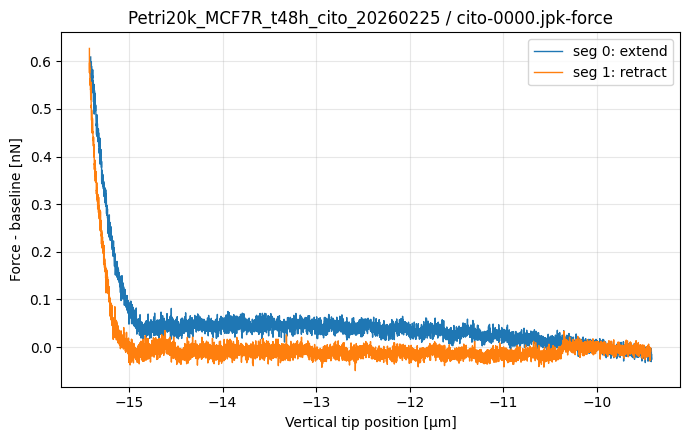

Group: Petri20k_MCF7R_t48h_nucleo_20260225


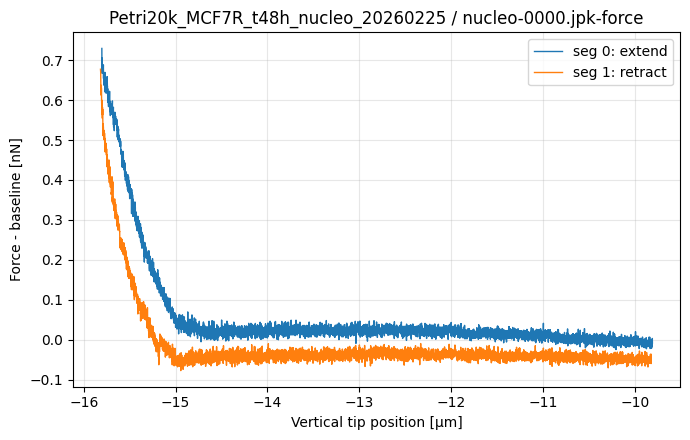

Group: T47DR_t48h_cito_20260318


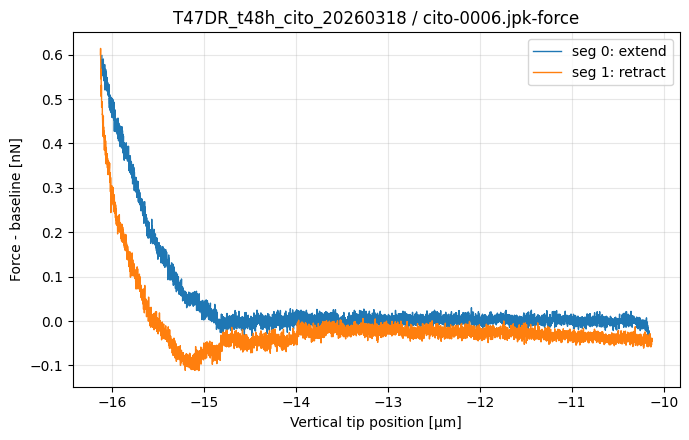

Group: T47DR_t48h_nucleo_20260318


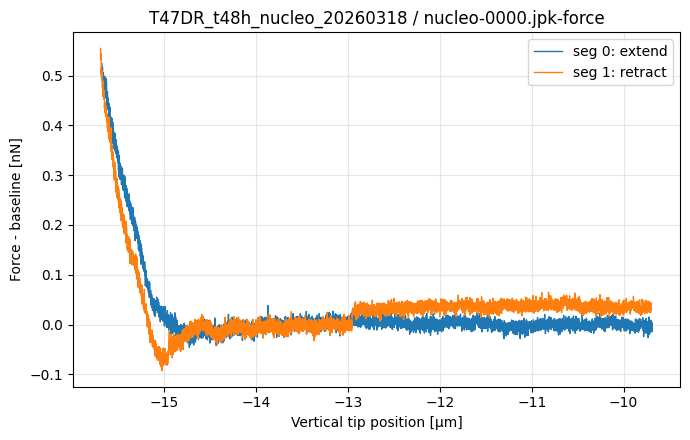

In [8]:
def plot_curve(file_path, save=False):
    fig, ax = plt.subplots(figsize=(7, 4.5))
    for seg in [0, 1]:
        try:
            df, meta, *_ = read_jpk_segment(file_path, segment_id=seg)
            nbase = max(10, int(0.2 * len(df)))
            baseline = np.nanmedian(df['force_nN'].iloc[:nbase])
            ax.plot(df['z_tip_um'], df['force_nN'] - baseline, lw=1, label=f"seg {seg}: {meta.get('segment_style')}")
        except Exception:
            continue
    ax.set_xlabel('Vertical tip position [µm]')
    ax.set_ylabel('Force - baseline [nN]')
    ax.set_title(f"{Path(file_path).parent.name} / {Path(file_path).name}")
    ax.grid(alpha=0.3)
    ax.legend()
    fig.tight_layout()
    if save:
        out = PLOTS_DIR / f"{Path(file_path).parent.name}__{Path(file_path).stem}.png"
        fig.savefig(out, dpi=160)
        plt.close(fig)
        return out
    plt.show()

# Mostra una curva per ciascun gruppo
for group, sub in file_table.groupby('group'):
    print("Group:", group)
    plot_curve(Path(sub.iloc[0]['path']), save=False)

In [9]:
# Salva un numero limitato di plot per gruppo, utile per sfogliare rapidamente i dati.
N_PLOTS_PER_GROUP = 8
saved = []
for group, sub in file_table.groupby('group'):
    for p in sub['path'].head(N_PLOTS_PER_GROUP):
        saved.append(plot_curve(Path(p), save=True))
print(f"Plot salvati: {len(saved)}")
print("Cartella:", PLOTS_DIR.resolve())

Plot salvati: 32
Cartella: C:\Users\giaco\OneDrive\Desktop\AFM\afm_output\plots_overview


## 6. Esportazione opzionale delle curve in CSV

Questa cella esporta le curve lette in una forma più semplice. Di default esporta solo il segmento 0, perché può generare molti file.

In [10]:
EXPORT_CSV = False  # metti True se vuoi esportare tutte le curve in CSV
SEGMENT_TO_EXPORT = 0

if EXPORT_CSV:
    exported = []
    for p in files:
        try:
            df, meta, *_ = read_jpk_segment(p, segment_id=SEGMENT_TO_EXPORT)
            group_dir = CSV_DIR / p.parent.name
            group_dir.mkdir(parents=True, exist_ok=True)
            out = group_dir / f"{p.stem}_segment{SEGMENT_TO_EXPORT}.csv"
            df.to_csv(out, index=False)
            exported.append(out)
        except Exception as e:
            print("Errore:", p, e)
    print(f"CSV esportati: {len(exported)}")
    print("Cartella:", CSV_DIR.resolve())
else:
    print("EXPORT_CSV=False: nessun CSV esportato.")

EXPORT_CSV=False: nessun CSV esportato.


## 7. Screening preliminare degli outlier

Questo non è ancora machine learning. È solo un controllo qualità iniziale basato su feature fisiche semplici.

Serve a identificare curve da guardare manualmente: rumore alto, forza massima molto diversa, numero di punti anomalo, ecc.

In [11]:
ok = summary[summary['status'] == 'ok'].copy()

# z-score robusto usando mediana e MAD
features_for_qc = ['force_corr_max_nN', 'baseline_noise_pN', 'z_range_um', 'n_points']
for col in features_for_qc:
    x = ok[col].astype(float)
    med = np.nanmedian(x)
    mad = np.nanmedian(np.abs(x - med))
    if mad == 0 or not np.isfinite(mad):
        ok[f'{col}_robust_z'] = np.nan
    else:
        ok[f'{col}_robust_z'] = 0.6745 * (x - med) / mad

zcols = [f'{c}_robust_z' for c in features_for_qc]
ok['qc_score'] = ok[zcols].abs().max(axis=1)
ok['qc_flag_simple'] = ok['qc_score'] > 3.5

qc_path = OUT_DIR / 'summary_segment0_with_qc.csv'
ok.to_csv(qc_path, index=False)
print("Salvato:", qc_path)
print("Curve flaggate dal controllo semplice:", int(ok['qc_flag_simple'].sum()), "/", len(ok))

display(ok.sort_values('qc_score', ascending=False).head(20)[
    ['group', 'file_name', 'force_corr_max_nN', 'baseline_noise_pN', 'z_range_um', 'n_points', 'qc_score', 'qc_flag_simple']
])

Salvato: afm_output\summary_segment0_with_qc.csv
Curve flaggate dal controllo semplice: 82 / 257


,group,file_name,force_corr_max_nN,baseline_noise_pN,z_range_um,n_points,qc_score,qc_flag_simple
192,T47DR_t48h_nucleo_20260318,nucleo-0020.jpk-force,0.703936,8.158006,4.029774,4037,825.313996,True
142,T47DR_t48h_cito_20260318,cito-0047.jpk-force,0.618417,11.347837,4.159080,4165,770.981779,True
209,T47DR_t48h_nucleo_20260318,nucleo-0038.jpk-force,0.576233,9.405771,4.359938,4366,686.585206,True
60,Petri20k_MCF7R_t48h_nucleo_20260225,nucleo-0006.jpk-force,0.612272,12.742021,4.433225,4437,655.791319,True
216,T47DR_t48h_nucleo_20260318,nucleo-0046.jpk-force,0.708181,9.981082,4.580278,4587,594.002151,True
170,T47DR_t48h_cito_20260318,cito-0086.jpk-force,0.716465,10.578939,4.581997,4589,593.279882,True
137,T47DR_t48h_cito_20260318,cito-0037.jpk-force,0.617466,8.564000,4.625384,4632,575.049274,True
205,T47DR_t48h_nucleo_20260318,nucleo-0034.jpk-force,0.439829,18.461013,4.692678,4698,546.773776,True
1,Petri20k_MCF7R_t48h_cito_20260225,cito-0005.jpk-force,0.706989,10.248385,4.696054,4700,545.355224,True
126,T47DR_t48h_cito_20260318,cito-0021.jpk-force,0.739601,11.832895,4.698016,4705,544.530920,True


C:\Users\giaco\AppData\Local\Temp\ipykernel_22440\2582509197.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


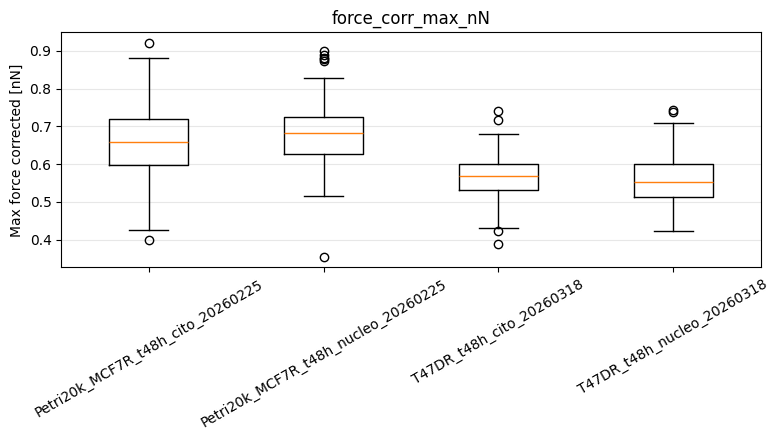

C:\Users\giaco\AppData\Local\Temp\ipykernel_22440\2582509197.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


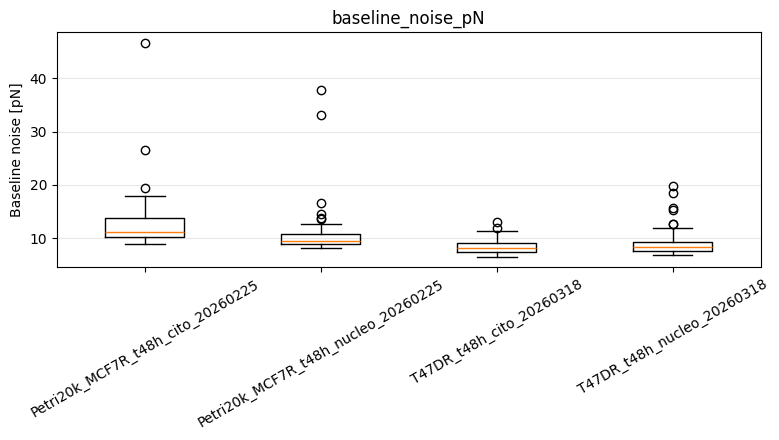

C:\Users\giaco\AppData\Local\Temp\ipykernel_22440\2582509197.py:10: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(data, labels=groups, showfliers=True)


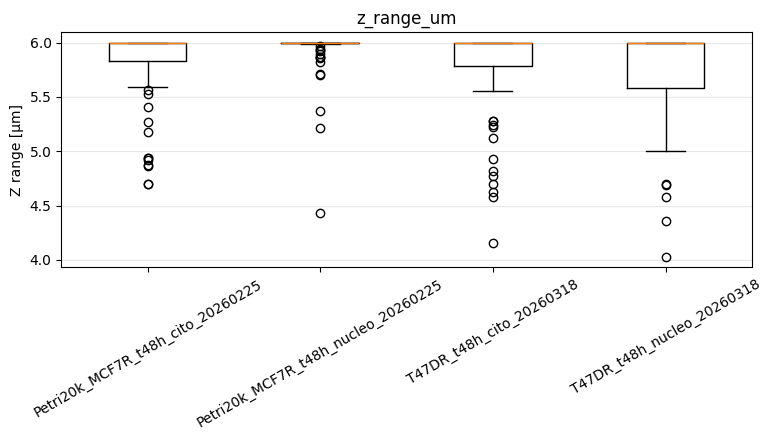

In [12]:
# Plot delle feature principali per gruppo
for col, ylabel in [
    ('force_corr_max_nN', 'Max force corrected [nN]'),
    ('baseline_noise_pN', 'Baseline noise [pN]'),
    ('z_range_um', 'Z range [µm]'),
]:
    fig, ax = plt.subplots(figsize=(8, 4.5))
    groups = list(ok['group'].dropna().unique())
    data = [ok.loc[ok['group'] == g, col].dropna().to_numpy() for g in groups]
    ax.boxplot(data, labels=groups, showfliers=True)
    ax.set_ylabel(ylabel)
    ax.set_title(col)
    ax.tick_params(axis='x', rotation=30)
    ax.grid(alpha=0.3, axis='y')
    fig.tight_layout()
    plt.show()

## 8. Prossimo step: fit fisico

Prima di implementare il fit Hertz-like finale, servono alcune conferme dal gruppo AFM:

1. Segmento da usare per il fit: `extend/approach` o `retract`?
2. Geometria della punta: sferica, conica, piramidale?
3. Raggio punta o semiangolo, se noto.
4. Valore di Poisson assunto per il campione.
5. Metodo manuale attuale: come scelgono punto di contatto e range di fit?
6. Alcune curve già analizzate manualmente con Young modulus e, se possibile, punto di contatto/range scelto.

Quando questi punti sono chiari, si può aggiungere una sezione:

```text
baseline correction -> contact point detection -> indentation -> Hertz fit -> E ± uncertainty
```